In [63]:
from pathlib import Path
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from scipy import sparse
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Your notebook is in the notebook/ folder
PROJECT_ROOT = Path.cwd().parent

MODEL_PATH = PROJECT_ROOT / "models" / "diabetes_pipeline.joblib"
X_TEST_PATH = PROJECT_ROOT / "data" / "processed" / "X_test.csv"
Y_TEST_PATH = PROJECT_ROOT / "data" / "processed" / "y_test.csv"

# Reports stay in the main project folder
METRICS_DIR = PROJECT_ROOT / "reports" / "metrics"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"

# Create only the output folder needed for XAI figures
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Check required input files
for path in [MODEL_PATH, X_TEST_PATH, Y_TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

# Load the saved artifact; do not retrain
artifact = joblib.load(MODEL_PATH)
pipeline = artifact["pipeline"]
model_name = artifact["model_name"]
selected_features = artifact["selected_features"]

# Load test data
X_test = pd.read_csv(X_TEST_PATH)
y_test = pd.read_csv(Y_TEST_PATH).squeeze()

print("Model:", model_name)
print("Pipeline steps:", list(pipeline.named_steps))
print("Selected features:", selected_features)
print("Test data:", X_test.shape, y_test.shape)

Model: xgboost
Pipeline steps: ['preprocessor', 'model']
Selected features: ['age', 'gender', 'pulse_rate', 'systolic_bp', 'diastolic_bp', 'glucose', 'bmi', 'family_diabetes', 'hypertensive', 'family_hypertension', 'cardiovascular_disease', 'stroke']
Test data: (1075, 12) (1075,)


#### Generate predictions and evaluate the model

In [64]:

# Use the existing fitted pipeline; do not retrain.
y_prob = pipeline.predict_proba(X_test)[:, 1]
y_pred = pipeline.predict(X_test)

print("Prediction completed.")
print("First 10 diabetes probabilities:", np.round(y_prob[:10], 4))
print("First 10 predicted classes:", y_pred[:10])

print("\nModel evaluation on the saved test set")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))


Prediction completed.
First 10 diabetes probabilities: [0.4459 0.0617 0.1393 0.1708 0.8482 0.0322 0.3891 0.2569 0.4446 0.0625]
First 10 predicted classes: [0 0 0 0 1 0 0 0 0 0]

Model evaluation on the saved test set
Accuracy: 0.8688
ROC-AUC: 0.8741

Classification report:
              precision    recall  f1-score   support

           0       0.98      0.88      0.93      1008
           1       0.29      0.76      0.42        67

    accuracy                           0.87      1075
   macro avg       0.64      0.82      0.67      1075
weighted avg       0.94      0.87      0.89      1075

Confusion matrix:
[[883 125]
 [ 16  51]]


#### Extract the preprocessing and XGBoost model

In [65]:

# Extract the already-fitted pipeline components.
preproc = pipeline.named_steps["preprocessor"]
model =     pipeline.named_steps["model"]

# Transform test data using the fitted preprocessor.
X_test_transformed = preproc.transform(X_test)

# SHAP plotting works more conveniently with a dense array.
if sparse.issparse(X_test_transformed):
    X_test_transformed = X_test_transformed.toarray()

feature_names = np.asarray(
    preproc.get_feature_names_out(),
    dtype=str
)

assert X_test_transformed.shape[1] == len(feature_names), (
    "Transformed data columns do not match feature names."
)

print("Transformed test shape:", X_test_transformed.shape)
print("Number of transformed features:", len(feature_names))
print("\nTransformed feature names:")

for feature in feature_names:
    print("-", feature)


Transformed test shape: (1075, 13)
Number of transformed features: 13

Transformed feature names:
- numeric__age
- numeric__pulse_rate
- numeric__systolic_bp
- numeric__diastolic_bp
- numeric__glucose
- numeric__bmi
- numeric__family_diabetes
- numeric__hypertensive
- numeric__family_hypertension
- numeric__cardiovascular_disease
- numeric__stroke
- categorical__gender_Female
- categorical__gender_Male


#### Calculate SHAP values

In [66]:

# Reproducible background and explanation samples.
rng = np.random.default_rng(42)

background_size = min(30, len(X_test_transformed))
background_indices = rng.choice(
    len(X_test_transformed),
    size=background_size,
    replace=False
)

X_background = X_test_transformed[background_indices]

explain_size = min(200, len(X_test_transformed))
X_explain = X_test_transformed[:explain_size]

# The fitted XGBoost model receives already-transformed features.
def predict_positive_probability(data):
    data = np.asarray(data)

    if data.ndim == 1:
        data = data.reshape(1, -1)

    return model.predict_proba(data)[:, 1]

# Model-agnostic permutation explainer.
explainer = shap.Explainer(
    predict_positive_probability,
    X_background,
    algorithm="permutation",
    feature_names=feature_names.tolist()
)

# Permutation SHAP needs enough evaluations to estimate feature contributions.
max_evals = 2 * X_explain.shape[1] + 1

print("Calculating SHAP values...")
print("Patients to explain:", len(X_explain))
print("Transformed features:", X_explain.shape[1])
print("Maximum evaluations per patient:", max_evals)

shap_explanation = explainer(
    X_explain,
    max_evals=max_evals
)

shap_array = np.asarray(shap_explanation.values)

assert shap_array.shape == X_explain.shape, (
    "Unexpected SHAP value shape."
)

print("\nSHAP calculation completed.")
print("SHAP values shape:", shap_array.shape)
print("Base values shape:", np.asarray(shap_explanation.base_values).shape)


Calculating SHAP values...


Patients to explain: 200
Transformed features: 13
Maximum evaluations per patient: 27

SHAP calculation completed.
SHAP values shape: (200, 13)
Base values shape: (200,)


#### SHAP summary beeswarm plot

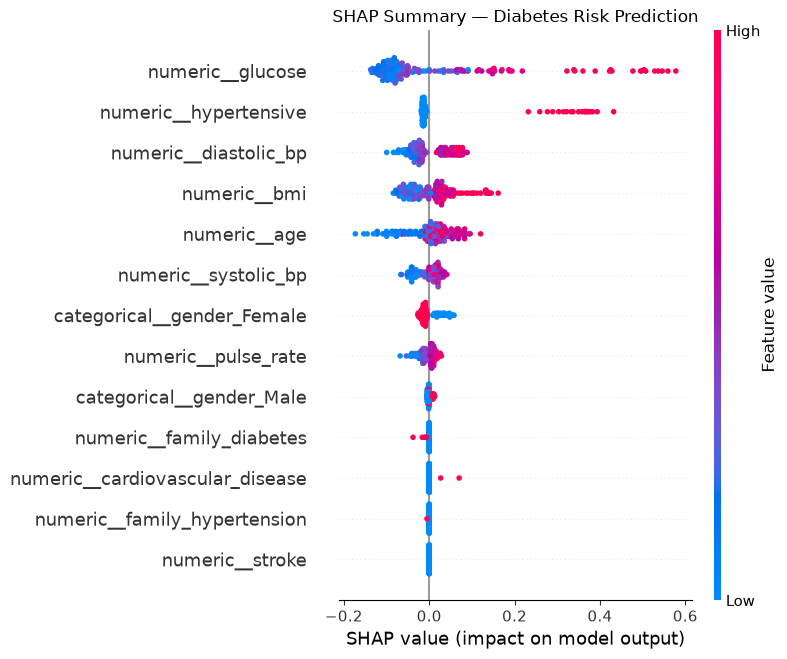

Saved: c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\figures\shap_summary_beeswarm.png


In [67]:

# Shows feature contributions across the explained patients.
shap.plots.beeswarm(
    shap_explanation,
    max_display=15,
    show=False
)

plt.title("SHAP Summary — Diabetes Risk Prediction")
plt.tight_layout()

summary_path = FIGURE_DIR / "shap_summary_beeswarm.png"
plt.savefig(summary_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("Saved:", summary_path)


#### Global feature importance

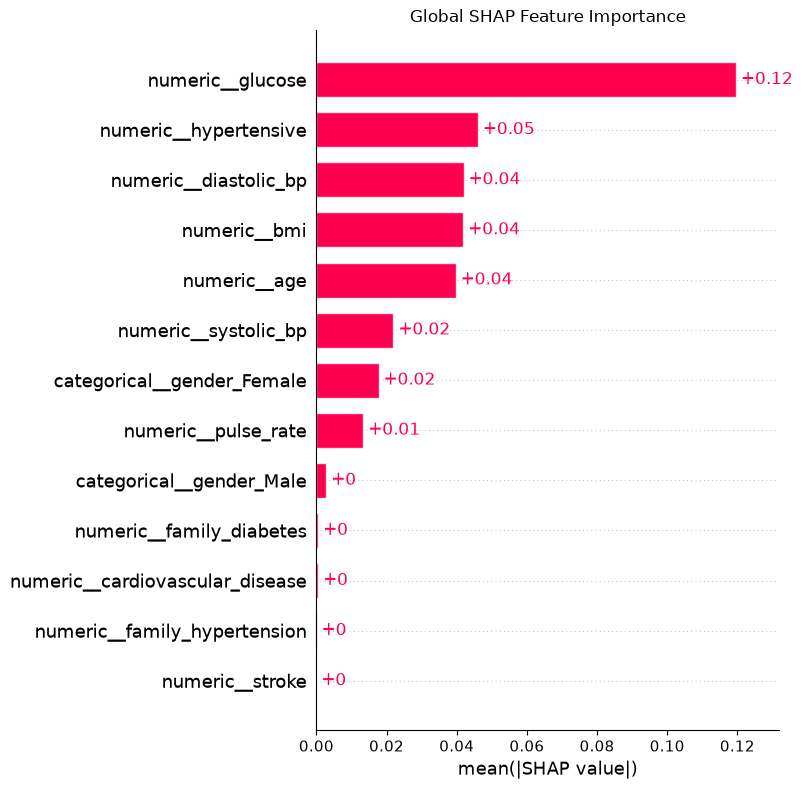

Top 15 transformed features:


,feature,mean_abs_shap
0,numeric__glucose,0.119605
1,numeric__hypertensive,0.046031
2,numeric__diastolic_bp,0.041947
3,numeric__bmi,0.041843
4,numeric__age,0.039694
5,numeric__systolic_bp,0.021955
6,categorical__gender_Female,0.017719
7,numeric__pulse_rate,0.013371
8,categorical__gender_Male,0.002821
9,numeric__family_diabetes,0.000502


Saved: c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\figures\shap_bar_importance.png
Saved: c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\metrics\shap_feature_importance.csv


In [68]:

# Mean absolute SHAP contribution for each transformed feature.
importance_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_array).mean(axis=0)
}).sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

# Bar plot using the same SHAP explanation.
shap.plots.bar(
    shap_explanation,
    max_display=15,
    show=False
)

plt.title("Global SHAP Feature Importance")
plt.tight_layout()

bar_path = FIGURE_DIR / "shap_bar_importance.png"
plt.savefig(bar_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# Save numeric feature importance.
importance_path = METRICS_DIR / "shap_feature_importance.csv"
importance_df.to_csv(importance_path, index=False)

print("Top 15 transformed features:")
display(importance_df.head(15))

print("Saved:", bar_path)
print("Saved:", importance_path)


#### Explain an individual patient's prediction

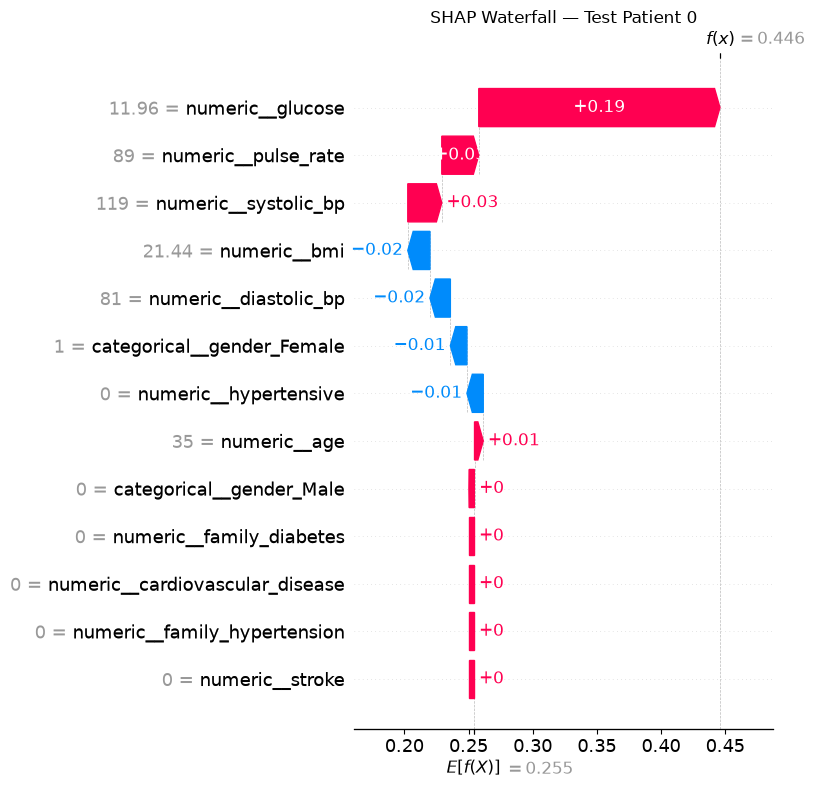

Test patient index: 0
Actual diabetes label: 0
Predicted class: 0
Predicted diabetes probability: 0.4459
Saved: c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\figures\shap_waterfall_sample.png


In [69]:

# Select one of the patients explained in Cell 3.
idx = 0

if not 0 <= idx < len(X_explain):
    raise IndexError("Selected patient index is outside the explained sample.")

sample_explanation = shap_explanation[idx]

shap.plots.waterfall(
    sample_explanation,
    max_display=15,
    show=False
)

plt.title(f"SHAP Waterfall — Test Patient {idx}")
plt.tight_layout()

waterfall_path = FIGURE_DIR / "shap_waterfall_sample.png"
plt.savefig(waterfall_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("Test patient index:", idx)
print("Actual diabetes label:", int(y_test.iloc[idx]))
print("Predicted class:", int(y_pred[idx]))
print("Predicted diabetes probability:", round(float(y_prob[idx]), 4))
print("Saved:", waterfall_path)


### SHAP dependence plot

Most important transformed feature: numeric__glucose
Mean absolute SHAP value: 0.119605


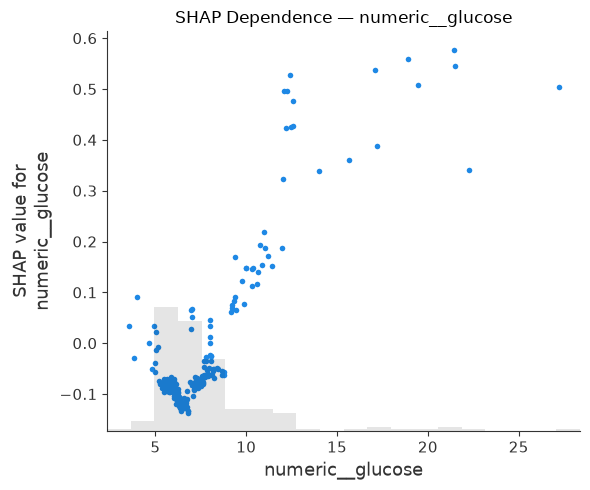

Saved: c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\figures\shap_dependence_numeric__glucose.png


In [70]:

# Select the feature with the largest mean absolute SHAP value.
top_feature = importance_df.iloc[0]["feature"]
feature_idx = list(feature_names).index(top_feature)

print("Most important transformed feature:", top_feature)
print(
    "Mean absolute SHAP value:",
    round(float(importance_df.iloc[0]["mean_abs_shap"]), 6)
)

# Plot feature values against their SHAP contributions.
shap.plots.scatter(
    shap_explanation[:, feature_idx],
    show=False
)

plt.title(f"SHAP Dependence — {top_feature}")
plt.tight_layout()

safe_feature_name = re.sub(
    r"[^A-Za-z0-9_-]+",
    "_",
    str(top_feature)
).strip("_")

dependence_path = (
    FIGURE_DIR / f"shap_dependence_{safe_feature_name}.png"
)

plt.savefig(dependence_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("Saved:", dependence_path)


In [71]:

# Save SHAP values for the explained patients.
shap_values_path = METRICS_DIR / "shap_values_first_200.npy"
np.save(shap_values_path, shap_array)

# Save the transformed feature names separately.
feature_names_path = METRICS_DIR / "shap_transformed_feature_names.csv"
pd.DataFrame({
    "feature": feature_names
}).to_csv(feature_names_path, index=False)

# Save a compact summary of the model and explanation.
summary = {
    "model_name": str(model_name),
    "test_patient_count": int(len(X_test)),
    "explained_patient_count": int(len(X_explain)),
    "original_feature_count": int(len(selected_features)),
    "transformed_feature_count": int(len(feature_names)),
    "test_accuracy": float(accuracy_score(y_test, y_pred)),
    "test_roc_auc": float(roc_auc_score(y_test, y_prob)),
    "top_10_features": importance_df.head(10)["feature"].tolist()
}

import json

summary_path = METRICS_DIR / "shap_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=4)

print("XAI analysis completed.")
print("\nTop 10 features:")
display(importance_df.head(10))

print("\nGenerated files:")
for path in [
    summary_path,
    shap_values_path,
    feature_names_path,
    importance_path,
    summary_path,
    FIGURE_DIR / "shap_summary_beeswarm.png",
    FIGURE_DIR / "shap_bar_importance.png",
    FIGURE_DIR / "shap_waterfall_sample.png",
    dependence_path
]:
    if path.exists():
        print(path)


XAI analysis completed.

Top 10 features:


,feature,mean_abs_shap
0,numeric__glucose,0.119605
1,numeric__hypertensive,0.046031
2,numeric__diastolic_bp,0.041947
3,numeric__bmi,0.041843
4,numeric__age,0.039694
5,numeric__systolic_bp,0.021955
6,categorical__gender_Female,0.017719
7,numeric__pulse_rate,0.013371
8,categorical__gender_Male,0.002821
9,numeric__family_diabetes,0.000502



Generated files:
c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\metrics\shap_summary.json
c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\metrics\shap_values_first_200.npy
c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\metrics\shap_transformed_feature_names.csv
c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\metrics\shap_feature_importance.csv
c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\metrics\shap_summary.json
c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\figures\shap_summary_beeswarm.png
c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\figures\shap_bar_importance.png
c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\figures\shap_waterfall_sample.png
c:\Users\vishnu\Desktop\diabetes-prediction-ml-main\reports\figures\shap_dependence_numeric__glucose.png
